# Revocation in delegated workflows
### A guided study report · Node & Norm
**Private research draft · Updated 7 November 2026**

> **The finding:** a request to stop, an effective withdrawal of authority, and confirmation to the person are different events. This study makes that difference inspectable in saved local executions.

The **twelve-case local study is complete within its declared scope**. Native Temporal qualification and human-reviewer evaluation are not complete. This notebook adds a reading surface, not new experimental results.

**Read in order:** question → method → evidence → interpretation → next steps → completion.

- **Five-minute reader:** read the short explanations and saved figures. No setup required.
- **Researcher:** inspect the evidence tables, source links and limits; then open [the interactive evidence workbench](notebooks/01_revocation_evidence_workbench.ipynb).
- **Engineer:** use the [offline run guide](notebooks/README.md). Run All reads preserved records, without a model API or experiment.

The sections below contain the report itself, not just a list of links. Original archives, protocols and implementation remain underneath for verification.
**Display note:** GitHub shows saved static notebook outputs. To change evidence selections, open in Jupyter, edit the selectors and rerun the relevant cells.


## 1 · What are we trying to understand?

A person withdraws authority after work has been delegated. The workflow may already have queued or checkpointed work. **What evidence lets us distinguish the request, enforcement, and the person's knowledge?**

| Event | Plain-language meaning | Not enough to conclude |
|---|---|---|
| Request accepted | The relay received the request. | Authority has changed. |
| Fence installed | The trusted local sink committed the authority change. | The caller knows this happened. |
| Caller confirmed | A matching completion envelope reached the caller. | Earlier effects were undone. |

A **protected effect** here is an inert operation recorded at the local sink, not an email, payment or external service action. These are established systems distinctions, not a claim of a new general principle.

[Executed question and boundary](docs/decisions/2026-11-03-request-to-fence-interface-study.md) · [Source definitions](docs/research-records/v0.1/glossary.json)

## 2 · How the pieces fit

**Scope → inspect evidence → challenge the interpretation → synthesize a bounded account.** This progression follows the readable learning pattern of LangChain's [Deep Research course](https://github.com/langchain-ai/deep_research_from_scratch).

The diagram below describes our **implemented offline evidence-review workflow**, not a live LangGraph team. The earlier integration pilot did use actual agent-framework checkpoint and human-in-the-loop machinery, with scripted responses. Those are different layers.

The small code cells are inspectable steps. Their saved outputs let readers follow the argument without executing anything.

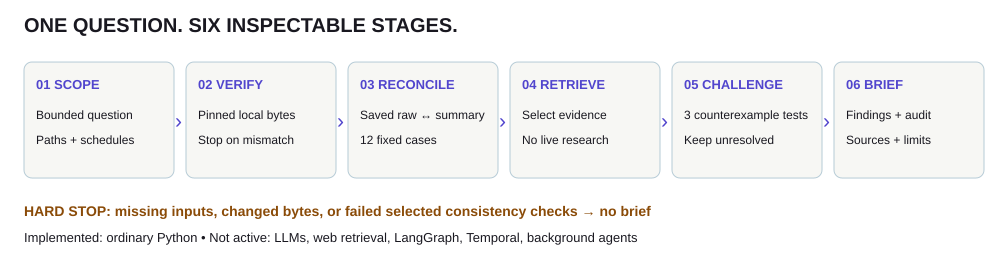

In [1]:
from pathlib import Path
import json
import sys

# Run from the repository root or notebooks/. No installation or environment secrets.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "docs/research-records/v0.1/source_manifest.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the complete repository checkout.")
sys.dont_write_bytecode = True
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))

from workbench.core import Scope, EvidenceError, run_workbench, barrier_rows, ARCHIVE, CHECKER
from workbench.presentation import (
    show, workflow_map, overview, glossary_view, source_inventory, case_matrix,
    claim_view, barrier_view, raw_json, excerpt, table, brief_view,
)
show(workflow_map())

### Keep the study stages separate

| Stage | Unit and result | What the stage establishes |
|---|---|---|
| v0.2 instrument qualification | 18 case-arm fixtures | Finite checks of seeded failures and intended denial mechanisms. |
| v0.3 framework integration | 8 fixed cases | Scripted framework checkpoint/resume conformance. |
| Request-to-fence study | 12 fixed cases, 6 schedules × 2 paths | Separation of request, sink state and caller knowledge. |
| Synthetic Temporal checker | Recorded 115 project tests + 26 separately authored regressions | Saved-artifact behavior, not native Temporal qualification. |
| Retrospective packet design | 8 derivative packets from 2 historical synthetic cases | Packet preparation, not human-reviewer benefit. |

**These counts are different units, not a pooled sample.** Separate AI-assisted review is not independent human validation.

[Qualification protocol](qualification/v0.2/PROTOCOL.md) · [Integration protocol](integration/v0.3/PROTOCOL.md) · [Checker package](docs/checker-implementation/2026-11-05/README.md) · [Packet record](docs/decisions/2026-11-03-retrospective-packet-qualification.md)

## 3 · Open the saved evidence

The next cell verifies the pinned inputs, opens the preserved archive in memory, and reconciles the twelve case records with the historical summary. It does **not** rerun the experiment.

The two execution paths share the same authority mechanism. They are matched conformance controls, not independent security implementations. A no-fence case is excluded from the conditional post-fence question.

In [2]:
scope = Scope(paths=("direct", "framework"), schedules=("S0", "S1", "S2", "S3", "S4", "S5"))
run = run_workbench(ROOT, scope)
evidence = run.evidence
show(overview(run))


Saved cases,Effects,Revoked denials,Fenced cases,Post-fence effects
12,6,6,8,0


In [3]:
show(case_matrix(run.rows))


Path / case,Acceptance,Sink fence,Caller,Effect / denial,After fence
direct / S0,none,none in window,IDLE (no request),effect: 7,N/A — no fence
direct / S1,volatile,seq 7,CONFIRMED,denied: revoked,0
direct / S2,volatile,seq 9,CONFIRMED,effect: 7,0
direct / S3,volatile,seq 7,CONFIRMED,denied: revoked,0
direct / S4,volatile,seq 7,UNCONFIRMED at window end,denied: revoked,0
direct / S5,volatile,none in window,UNCONFIRMED at window end,effect: 7,N/A — no fence
framework / S0,none,none in window,IDLE (no request),effect: 7,N/A — no fence
framework / S1,volatile,seq 7,CONFIRMED,denied: revoked,0
framework / S2,volatile,seq 9,CONFIRMED,effect: 7,0
framework / S3,volatile,seq 7,CONFIRMED,denied: revoked,0


### What each schedule contributes

- **S0:** legitimate work commits without a withdrawal request.
- **S1:** fence and confirmation precede the protected attempt; it is denied.
- **S2:** an effect commits before the fence; later withdrawal does not roll it back.
- **S3:** the fence stops execution before confirmation arrives.
- **S4:** the fence stops execution, but confirmation is withheld.
- **S5:** request delivery is withheld; no fence is installed in the window and an effect commits.

All twelve cases matched the frozen expectations: six effects and six revoked denials. **That is not a reliability estimate.** The schedules were deliberately selected, not sampled from production.

[Measured summary](docs/review/WITHDRAWAL_INTERFACE_SUMMARY_v0.1.json) · [Post-run review](docs/review/WITHDRAWAL_INTERFACE_POSTRUN_REVIEW_v0.1.md)

## 4 · The decisive contrast: same uncertainty, different reality

In **S4 and S5**, the caller reaches observation end without valid confirmation. Yet the sink states differ. The next figures come from the saved direct-path records; they are not illustrative invented histories.

Read the caller and sink lanes separately. Sequence numbers express local sink transaction order, not elapsed time.

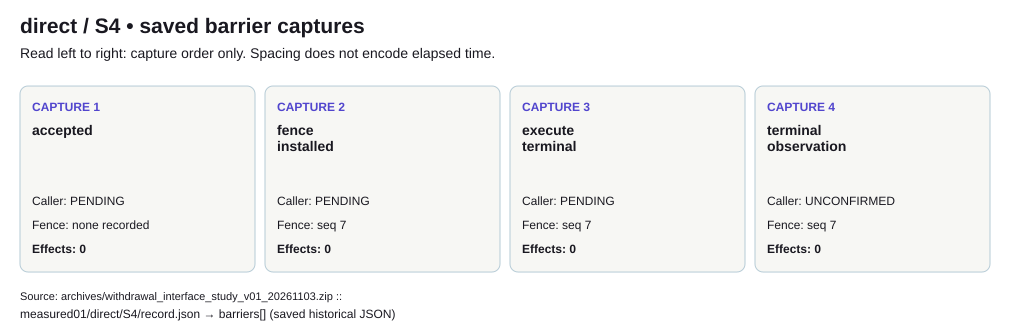

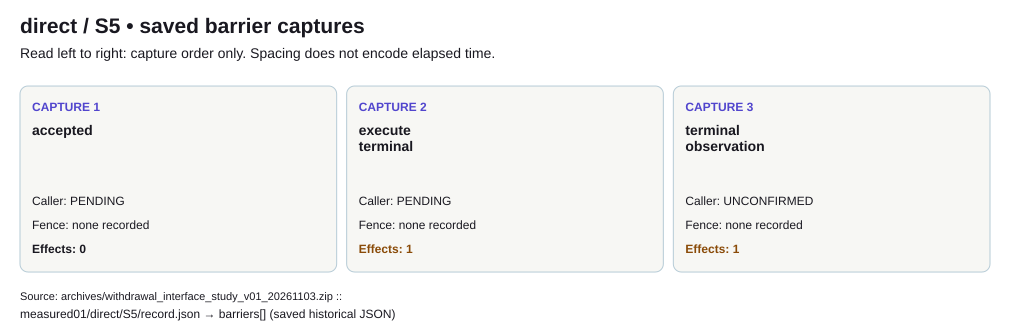

In [4]:
for schedule in ("S4", "S5"):
    show(barrier_view(evidence.case("direct", schedule)))


### What follows, and what does not

**Supported within the fixture:** caller uncertainty alone cannot identify sink state. Request receipt alone cannot establish enforcement. Withdrawal is not rollback.

**Not supported:** that any production vendor failed; that these controls confine hostile workers; that latency, human cognition or population reliability has been measured.

The trusted gateway and effects share one SQLite transaction domain and OS user. There is at most one outstanding withdrawal request. The completion envelope is fixture provenance, not a signed remote certificate.

[Reproduction and limits](docs/review/WITHDRAWAL_INTERFACE_LOCAL_REPRODUCTION_v0.1.md) · [Separately authored AI-assisted audit](docs/review/WITHDRAWAL_INTERFACE_PROTOCOL_FIRST_AUDIT_v0.1.md)

## 5 · Challenge the interpretation before accepting it

These deterministic counterexample queries examine the selected saved cases. They are not an LLM judge. A witness refutes an overclaim **within this collection**; a query finding no witness would not prove a universal claim.

In [5]:
show(table(["Claim", "Proposition under test", "Result", "Witnesses"],
           [[c["claim_id"], c["proposition"], c["status"], ", ".join(c["witnesses"]) or "none in selection"]
            for c in run.challenges], title="Fixed counterexample queries"))

Claim,Proposition under test,Result,Witnesses
C1,Unconfirmed at observation end means no fence was installed.,counterexample in selected records,"direct/S4, framework/S4"
C2,Unconfirmed at observation end means a fence was installed.,counterexample in selected records,"direct/S5, framework/S5"
C3,Caller confirmation means no effect occurred in the window.,counterexample in selected records,"direct/S2, framework/S2"


### Follow a displayed result to its source

This is the exact caller trace for direct-path S4, with its archive-member and field locator. The [full workbench](notebooks/01_revocation_evidence_workbench.ipynb) lets you change cases, inspect other fields and review source passages.

In [6]:
show(raw_json(evidence.case("direct", "S4")["caller_trace"],
              "Source JSON · direct / S4 · caller_trace",
              f"{ARCHIVE} :: measured01/direct/S4/record.json → caller_trace"))


Source JSON · direct / S4 · caller_trace
archives/withdrawal_interface_study_v01_20261103.zip :: measured01/direct/S4/record.json → caller_trace
[
  {
    "input": {
      "kind": "issue",
      "request_id": "withdrawal-1"
    },
    "before": "IDLE",
    "after": "PENDING"
  },
  {
    "input": {
      "kind": "accepted_volatile",
      "request_id": "withdrawal-1"
    },
    "before": "PENDING",
    "after": "PENDING"
  },
  {
    "input": {
      "kind": "observation_end"
    },
    "before": "PENDING",
    "after": "UNCONFIRMED_AT_OBSERVATION_END"
  }
]

## 6 · Where we are now

The following is an **editorial readiness assessment**, not the output of a runtime qualification checker. Missing evidence stays open; saved synthetic tests do not fill native-runtime gaps.

| Workstream | Current position | Evidence needed for the next gate |
|---|---|---|
| Local request-to-fence study | Bounded collection complete | Maintain source-linked account, corrections and reproducibility instructions. |
| Notebook reading surface | Guided saved-evidence report | Review intended rendering; clean Jupyter-kernel execution remains separately unverified. |
| Temporal bridge | Qualification blocked | Permitted runtime and observed bridge controls; no bypass of the denied socket operation. |
| Production exporter and capture | Not established | Real records with identity bindings, source acknowledgments and independently checked phase boundaries. |
| Native outcomes and deadlines | Unobserved / uncalibrated | Reviewed Workflow/Activity/worker mappings and justified observation cutoff. |
| Cleanup acceptance | Qualification evidence incomplete | Separate cleanup result and explicit eligibility rule; cleanup cannot backfill earlier evidence. |
| Human-review study | Evaluation unperformed | Frozen task, comparator, retrieval/review budget, reference judgments, leakage controls and separate authorization. |

Treatment evidence must be captured while the workflow is open; final outcome and shutdown are separate phases. A shutdown must not be used to claim that cancellation had already stopped execution.

[Temporal status](docs/decisions/2026-11-04-temporal-partial-qualification.md) · [Methods review](docs/review/TEMPORAL_METHODS_REVIEW_20261104.md) · [Checker implementation limits](docs/checker-implementation/2026-11-05/README.md)

## 7 · The route forward

### Now · make the completed work inspectable
**Deliverable:** this guided report plus the focused evidence workbench, attached to original sources. Preserve denominators, failed controls, limits and corrections. Update dated reports rather than silently rewriting historical records.

### Next · qualify the question before adding experiments
**Deliverable:** a feasibility account for independent reconstruction of why an AI-assisted decision was approved, including useful next-evidence requests under limited review time. Compare against competent source-linked summaries and checklists. The existing packet material is development data, not untouched held-out evidence.

This adjacent direction is **not an extra result of the revocation study**. Stop or narrow it if a retained export or strong baseline already solves the useful problem. Prior art already covers incomplete logs, abstention and provenance; novelty is not presumed.

### Conditional · extend only through explicit gates
**Deliverable:** native Temporal qualification in a permitted environment, followed only then by a separately approved measured protocol if it remains useful. Reviewer evaluation likewise needs its own approved protocol. No new model calls, participants, runtime tests or public release are authorized by this presentation update.

There is no promised date for blocked qualification. Mark makes research decisions; Alfred coordinates AI-assisted preparation and review. Named team responsibilities do not imply an already-running autonomous agent system.

## 8 · When can we call it complete?

| Bounded workstream | Completion or stopping rule |
|---|---|
| Local study | Frozen question, methods, twelve-case results, corrections, sources, reproduction instructions and limits form a reviewable closure package. The collection is already complete. |
| Temporal extension | Declared qualification and approved comparison completed and reviewed, **or** an explicit documented defer/stop decision. A stop is not a qualification pass. |
| Independent-reviewer study | Its own approved protocol and analysis completed, **or** a documented feasibility stop. Neither outcome is claimed today. |

An unfavorable result or justified uncertainty can complete a study. Completion does not mean every mechanism is safe. The wider research program continues only through separately bounded questions, not an endlessly expanding definition of this study.

## 9 · Who does what, and who decides?

**Human direction → bounded AI assignments → source checks and critical review → a decision for Mark.** This is the documented working arrangement, not evidence of a persistent autonomous team runtime.

| Responsibility | Contribution | Authority and review boundary |
|---|---|---|
| Mark Julius Banasihan · human research lead | Chooses questions, judges significance, resolves scope and release decisions. | Authorization is distinct from verifying every artifact; exhaustive human review is not claimed. |
| Alfred · AI coordinator | Frames bounded assignments, integrates results and surfaces disagreements. | Does not convert model agreement into established evidence or independent human validation. |
| Evidence researcher · assignment role | Reads primary sources, maps prior art and competing explanations. | Separates quotations, source statements and inference; records inaccessible sources. |
| Methods researcher · assignment role | Specifies cases, baselines, measurements and rejection criteria. | A proposed protocol is not an executed study. |
| Critical reviewer · assignment role | Checks claims against original evidence; searches for leakage and counterexamples. | Separately authored AI-assisted review may share models or assumptions. |
| Data, environment, quality and integrity specialists | Proposed capacity for provenance, reproducibility, controls and release review. | Planned responsibilities, not evidence that dedicated agents are staffed or running. |

The study records identify responsibilities, not a verified permanent assignment of SORA, MIRA or TRACE to each role. We should not retrofit those names onto historical work without an assignment record.

Each handoff should carry **question, input versions, permitted actions, deliverable, uncertainty and stopping condition**. Review findings should be corrected, accepted as a limitation, left unresolved, or rejected with evidence. Disagreement survives the handoff rather than disappearing into a polished summary.

Sources: [Team charter: responsibilities and review](docs/team/CHARTER.md#responsibilities-and-review) · [Assignment workflow](docs/team/WORKFLOW.md) · [Operating-stack overview](docs/team/OPERATING_STACK.md#system-overview). These are dated operating records; future staffing and enforcement require their own evidence.

## 10 · What is technically implemented?

Keep three layers distinct: **how we organize research**, **how this notebook reads evidence**, and **what the experimental instrument executed**.

| Layer | Mechanism | Evidence and limit |
|---|---|---|
| Research process | Scope → evidence → challenge → synthesis; explicit handoffs and review. | Documented assignments, not an automatically enforced LangGraph research runtime. |
| Notebook report | Python calls shared `workbench` functions; verifies pinned source bytes; reads saved archive members in memory. | Deterministic offline view. No model/API call or new runtime evidence. Saved output is a preview, not a live service. |
| Framework pilot | Actual `create_agent`, supervisor/subagent, HITL middleware and SQLite-backed checkpoints; scripted model responses. | Eight fixed integration cases, not autonomous planning or live model evaluation. |
| Authority boundary | Trusted gateway checks authority when committing a protected local effect; revocation and effects share one SQLite transaction domain. | Assumed mediation on one host, not hostile-worker confinement or distributed closure. |
| Resume boundary | Graceful worker exit and fresh-process resume while the gateway remains alive; trusted controller reattaches authority references. | Checkpoint restores action state, not permission. Not arbitrary crash recovery or gateway durability. |
| Artifact checker | Independent saved-file checks separate collection, treatment, assertion, qualification and cleanup. | Synthetic-only Temporal artifacts; not an exporter or evidence of native cancellation outcomes. |

**Pinned framework versions in the v0.3 record:** LangChain `1.4.7`, LangGraph `1.2.19`, checkpoint package `4.3.1`, SQLite checkpoint package `3.1.3`. These are historical environment pins, not a claim about current upstream releases. A dependency's presence, including LangSmith, does not prove that its hosted service was used.

The compact repo is for inspection; the original archives preserve fuller raw databases, fixtures and source snapshots. Reproduction requires the declared layout and dependencies. No install or new experiment is needed merely to read this report.

Inspect: [workflow implementation](integration/v0.3/workflow.py) · [runner](integration/v0.3/runner.py) · [protocol](integration/v0.3/PROTOCOL.md) · [version lock](integration/v0.3/requirements.lock) · [hashed dependency lock](integration/v0.3/requirements.hashed.txt) · [source pins](integration/v0.3/evidence/source_pins.json) · [workbench implementation](notebooks/workbench/core.py).

**Jev boundary:** proposed for semantic judgments in this study and deferred from this notebook build. Separate TAE × Jev work already involved live model use; it is not evidence of calibration or benefit here. Deterministic identity, digest, binding and authority checks remain distinct from semantic judgment. [Recorded Jev plan and limits](docs/team/CHARTER.md#planned-use-of-typesafe-ais-jev).
[Notebook 03: inspect the actual method, source freeze and reproduction requirements](notebooks/03_methods_and_reproduction.ipynb), without rerunning the study.


## 11 · How decisions and AI assistance stay visible

A readable report must expose the decisions behind it, not hide them. The [decision records](docs/decisions/) and [traceability workbook v0.11](docs/traceability/Revocation_AI_Use_and_Research_Decision_Traceability_v0.11.xlsx) preserve the historical question, approved scope, corrections and AI-use account. The workbook is the current **recorded historical snapshot**, not a claim that every later activity is already entered there.

| Record to retain | What another reader should be able to distinguish |
|---|---|
| Human decision | What Mark authorized, its scope and remaining uncertainty, versus what he independently checked. |
| AI contribution | Source analysis, method design, implementation, artifact review and synthesis, with exact models/tools where recorded. Unknown model versions must remain unknown, not be invented. |
| Claim and source | Extracted facts versus calculations, interpretations, proposals and unresolved claims; exact source/version. |
| Check and correction | Method, result, independence limits, affected artifacts and retained earlier failures. |
| Release decision | Audience, rights, private identifiers and disclosure review. Private maintenance is not publication permission. |

**This report's disclosure:** AI prepared the narrative and code changes; a separate AI-assisted reviewer checked content and reran the tests. This is not independent human validation, participant evidence or proof of improved reader comprehension. Test/replay methods and remaining display limitations are in the [verification record](notebooks/STUDY_REPORT_VERIFICATION.md).

Do not infer approval quality from a later bad outcome, cognition from screen access, or compliance from a mapped control. Source-linked explanations make review possible; they do not replace the review.

The source [workflow](docs/team/WORKFLOW.md#8-deliver-a-decision-brief-and-handoff) calls for contributor roles, input versions, evidence, checks, disagreements and the authorized next step. [AI-disclosure guidance in the operating stack](docs/team/OPERATING_STACK.md#ai-disclosure-and-research-integrity) remains a dated record, not newly verified policy guidance.
[Explore all six traceability and disclosure sheets in Notebook 02](notebooks/02_traceability_and_disclosure.ipynb), with exact source cells and dated status boundaries.


## 12 · Provenance, preservation and reading further

The input audit below identifies the actual files used by the executable report. Digests check byte identity, not truth, authenticity or tamper-proof attestation.

- [Dated synthesis, 6 November](docs/reports/2026-11-06-current-study-synthesis.md): preserved prior report snapshot.
- [Evidence workbench](notebooks/01_revocation_evidence_workbench.ipynb): case controls, glossary, source excerpts and synthetic checker demonstration.
- [Repository record](README.md): full historical navigation and reproduction instructions.
- [Verification for this notebook](notebooks/STUDY_REPORT_VERIFICATION.md): exactly what was checked and not checked.

This is the current guided report edition. Future substantive updates should date the account and retain Git history; the original source records are not replaced by notebook outputs. Historical registry statements remain historical, even when later implementation changes status.

**AI assistance:** framing, implementation, review and synthesis were AI-assisted. No exhaustive human verification or measured human-review benefit is claimed. **Private draft:** public sharing, licensing and publication need separate review.

In [7]:
show(table(["Input check", "Result"], [
    ["Pinned inputs", f"{len(evidence.receipts)} byte matches"],
    ["Original source snapshots", f"{len(evidence.sources)} byte matches"],
    ["Saved cases", str(len(run.rows))],
], title="Report input audit"))
show(source_inventory(evidence))


Input check,Result
Pinned inputs,76 byte matches
Original source snapshots,10 byte matches
Saved cases,12


Source key,Kind,Repository locator,SHA-256 (prefix)
reconciliation,current source review,docs/research-records/v0.1/sources/reconciliation.md,ce9ff80337554432
temporal_contract,proposed contract,docs/review/TEMPORAL_STATUS_EVIDENCE_CONTRACT_v01.md,b65e6422f80c4e44
temporal_status,partial execution status,docs/research-records/v0.1/sources/temporal_status.md,de63522cf6db0d16
runtime_setup,setup report,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/runtime_setup/QUALIFICATION_SUMMARY.md,2b0df6c1b1457228
withdrawal_protocol,historical protocol; later result status supersedes drafting status,docs/review/WITHDRAWAL_INTERFACE_PROTOCOL_v0.1.md,fdf9c7e0190ff39b
withdrawal_summary,historical result summary,docs/review/WITHDRAWAL_INTERFACE_SUMMARY_v0.1.json,273d485b72bc2332
withdrawal_review,historical AI-assisted audit report,docs/review/WITHDRAWAL_INTERFACE_POSTRUN_REVIEW_v0.1.md,98dc38ffa7fada19
methods_review,independent AI-assisted source review,docs/review/TEMPORAL_METHODS_REVIEW_20261104.md,ab6001b2d6c56b04
schema_log,schema-only test log,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/bridge_qualification/logs/q1_schema.txt,118c3ab1a6b77c17
blocked_control_log,failed bridge control log,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/bridge_qualification/logs/q2.txt,36d3bcc5c99375dd
